# پروژه TSP با الگوریتم ژنتیک


## وارد کردن کتابخانه‌ها

کتابخانه آماده الگوریتم ژنتیک استفاده نشده و بخش‌های اصلی الگوریتم دستی پیاده‌سازی شده‌اند.

In [1]:
import os
import time
import random
import csv
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


## تنظیمات الگوریتم

پارامترهای اصلی مثل اندازه جمعیت، تعداد نسل‌ها، نرخ جهش و نرخ تقاطع در این بخش قرار دارند.

In [2]:
@dataclass
class GAConfig:
    population_size: int = 200
    generations: int = 500
    crossover_rate: float = 0.9
    mutation_rate: float = 0.2
    tournament_size: int = 5
    elitism_count: int = 2
    mutation_type: str = "swap"
    seed: int = 42


## کلاس اصلی حل TSP

در این کلاس، ماتریس فاصله، جمعیت اولیه، Fitness، انتخاب، تقاطع OX، جهش، تولید نسل بعدی و رسم خروجی‌ها پیاده‌سازی شده‌اند.

In [3]:
class GeneticTSP:
    def __init__(self, cities, config=None):
        self.cities = np.array(cities, dtype=float)
        self.num_cities = len(self.cities)
        self.config = config if config is not None else GAConfig()

        # برای اینکه هر بار اجرای برنامه تقریباً همان نتیجه قبلی را بدهد، seed را ثابت می‌کنم.
        random.seed(self.config.seed)
        np.random.seed(self.config.seed)

        # قبل از شروع الگوریتم، فاصله همه شهرها را یک بار حساب می‌کنم تا بعد سریع‌تر به آن‌ها دسترسی داشته باشم.
        self.distance_matrix = self.create_distance_matrix()

        self.population = []
        self.best_chromosome = None
        self.best_distance = float("inf")
        self.best_history = []

    def create_distance_matrix(self):
        distance_matrix = np.zeros((self.num_cities, self.num_cities))

        for i in range(self.num_cities):
            for j in range(self.num_cities):
                x1, y1 = self.cities[i]
                x2, y2 = self.cities[j]
                distance_matrix[i][j] = np.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

        return distance_matrix

    def create_initial_population(self):
        self.population = []

        for _ in range(self.config.population_size):
            # هر جواب یک ترتیب کامل از شهرهاست؛ shuffle باعث می‌شود شهر تکراری یا حذف‌شده نداشته باشیم.
            chromosome = list(range(self.num_cities))
            random.shuffle(chromosome)
            self.population.append(chromosome)

    def calculate_route_distance(self, chromosome):
        total_distance = 0.0

        # فاصله شهرهای پشت سر هم در مسیر را جمع می‌کنم.
        for i in range(self.num_cities - 1):
            current_city = chromosome[i]
            next_city = chromosome[i + 1]
            total_distance += self.distance_matrix[current_city][next_city]

        # چون در TSP مسیر باید دوباره به شهر شروع برگردد، فاصله شهر آخر تا شهر اول هم اضافه می‌شود.
        last_city = chromosome[-1]
        first_city = chromosome[0]
        total_distance += self.distance_matrix[last_city][first_city]

        return total_distance

    def fitness(self, chromosome):
        # مسیر کوتاه‌تر باید امتیاز بیشتری بگیرد؛ بنابراین برازش را عکس طول مسیر در نظر می‌گیرم.
        route_distance = self.calculate_route_distance(chromosome)
        return 1.0 / route_distance

    def evaluate_population(self):
        distances = np.array([self.calculate_route_distance(chromosome) for chromosome in self.population])
        fitness_values = 1.0 / distances

        best_index = np.argmin(distances)

        # بهترین جواب کل اجرا را نگه می‌دارم، نه فقط بهترین جواب نسل فعلی.
        if distances[best_index] < self.best_distance:
            self.best_distance = distances[best_index]
            self.best_chromosome = self.population[best_index].copy()

        self.best_history.append(self.best_distance)

        return distances, fitness_values

    def tournament_selection(self):
        # در انتخاب تورنمنت چند کروموزوم را تصادفی انتخاب می‌کنم
        # و کروموزومی که Fitness بیشتری دارد به عنوان والد انتخاب می‌شود.
        selected_indices = random.sample(range(len(self.population)), self.config.tournament_size)

        best_index = selected_indices[0]
        best_fitness = self.fitness(self.population[best_index])

        for index in selected_indices[1:]:
            current_fitness = self.fitness(self.population[index])

            if current_fitness > best_fitness:
                best_fitness = current_fitness
                best_index = index

        return self.population[best_index].copy()

    def order_crossover(self, parent1, parent2):
        size = len(parent1)

        start, end = sorted(random.sample(range(size), 2))
        child = [None] * size

        # یک تکه از والد اول را مستقیم در فرزند می‌گذارم.
        child[start:end + 1] = parent1[start:end + 1]

        # بقیه جای خالی‌ها با ترتیب شهرهای والد دوم پر می‌شود، ولی شهر تکراری وارد فرزند نمی‌شود.
        current_position = (end + 1) % size

        for gene in parent2[end + 1:] + parent2[:end + 1]:
            if gene not in child:
                child[current_position] = gene
                current_position = (current_position + 1) % size

        return child

    def swap_mutation(self, chromosome):
        # در جهش تعویضی فقط جای دو شهر را عوض می‌کنم؛ پس کروموزوم همچنان معتبر می‌ماند.
        index1, index2 = random.sample(range(len(chromosome)), 2)
        chromosome[index1], chromosome[index2] = chromosome[index2], chromosome[index1]
        return chromosome

    def inversion_mutation(self, chromosome):
        # در این جهش یک بخش از مسیر را برعکس می‌کنم. این روش برای مسیرهای TSP معمولاً مفید است.
        index1, index2 = sorted(random.sample(range(len(chromosome)), 2))
        chromosome[index1:index2 + 1] = reversed(chromosome[index1:index2 + 1])
        return chromosome

    def mutate(self, chromosome):
        # جهش همیشه انجام نمی‌شود؛ فقط با احتمالی که در تنظیمات داده شده اعمال می‌شود.
        if random.random() < self.config.mutation_rate:
            if self.config.mutation_type == "inversion":
                chromosome = self.inversion_mutation(chromosome)
            else:
                chromosome = self.swap_mutation(chromosome)

        return chromosome

    def create_next_generation(self):
        distances, _ = self.evaluate_population()
        sorted_indices = np.argsort(distances)
        next_generation = []

        # چند جواب برتر را بدون تغییر به نسل بعد می‌برم تا بهترین جواب از بین نرود.
        for i in range(self.config.elitism_count):
            elite_index = sorted_indices[i]
            next_generation.append(self.population[elite_index].copy())

        # بقیه نسل جدید با انتخاب والد، تقاطع و جهش ساخته می‌شود.
        while len(next_generation) < self.config.population_size:
            parent1 = self.tournament_selection()
            parent2 = self.tournament_selection()

            if random.random() < self.config.crossover_rate:
                child1 = self.order_crossover(parent1, parent2)
                child2 = self.order_crossover(parent2, parent1)
            else:
                child1 = parent1.copy()
                child2 = parent2.copy()

            child1 = self.mutate(child1)
            child2 = self.mutate(child2)

            next_generation.append(child1)

            if len(next_generation) < self.config.population_size:
                next_generation.append(child2)

        self.population = next_generation

    def run(self):
        self.create_initial_population()

        for _ in range(self.config.generations):
            self.create_next_generation()

        # بعد از آخرین نسل هم یک بار ارزیابی انجام می‌دهم تا نتیجه نهایی ثبت شود.
        self.evaluate_population()

        return self.best_chromosome, self.best_distance, self.best_history

    def plot_convergence(self, save_path):
        plt.figure(figsize=(10, 6))
        plt.plot(self.best_history)
        plt.title("GA Convergence for TSP")
        plt.xlabel("Generation")
        plt.ylabel("Best Distance")
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(save_path, dpi=300)
        plt.show()

    def plot_best_route(self, save_path):
        if self.best_chromosome is None:
            raise ValueError("Algorithm has not been run yet.")

        # برای رسم مسیر بسته، شهر اول را به انتهای مسیر اضافه می‌کنم.
        route = self.best_chromosome + [self.best_chromosome[0]]
        route_coordinates = self.cities[route]

        plt.figure(figsize=(8, 8))
        plt.scatter(self.cities[:, 0], self.cities[:, 1], s=40)

        # شماره شهرها را روی شکل می‌نویسم تا مسیر در گزارش قابل فهم‌تر باشد.
        for i, (x, y) in enumerate(self.cities):
            plt.text(x, y, str(i + 1), fontsize=9, ha="right", va="bottom")

        plt.plot(route_coordinates[:, 0], route_coordinates[:, 1], linewidth=1.5)

        plt.title(f"Best TSP Route - Distance = {self.best_distance:.2f}")
        plt.xlabel("X")
        plt.ylabel("Y")
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(save_path, dpi=300)
        plt.show()


    def create_route_gif(self, save_path, interval=350, fps=3):
        if self.best_chromosome is None:
            raise ValueError("Algorithm has not been run yet.")

        # این تابع مسیر نهایی را مرحله‌به‌مرحله رسم می‌کند و خروجی را به صورت GIF ذخیره می‌کند.
        route = self.best_chromosome + [self.best_chromosome[0]]
        route_coordinates = self.cities[route]

        fig, ax = plt.subplots(figsize=(8, 8))

        ax.scatter(self.cities[:, 0], self.cities[:, 1], s=40)

        # شماره شهرها برای خوانایی بیشتر روی نقاط نوشته می‌شود.
        for i, (x, y) in enumerate(self.cities):
            ax.text(x, y, str(i + 1), fontsize=8, ha="right", va="bottom")

        ax.set_title(f"Best TSP Route Animation - Distance = {self.best_distance:.2f}")
        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.grid(True)

        x_min, x_max = self.cities[:, 0].min(), self.cities[:, 0].max()
        y_min, y_max = self.cities[:, 1].min(), self.cities[:, 1].max()
        margin = 5

        ax.set_xlim(x_min - margin, x_max + margin)
        ax.set_ylim(y_min - margin, y_max + margin)

        line, = ax.plot([], [], linewidth=1.8)

        def update(frame):
            # در هر فریم، یک بخش بزرگ‌تر از مسیر نمایش داده می‌شود.
            current_route = route_coordinates[:frame + 1]
            line.set_data(current_route[:, 0], current_route[:, 1])
            return line,

        animation = FuncAnimation(
            fig,
            update,
            frames=len(route_coordinates),
            interval=interval,
            blit=True,
            repeat=True
        )

        animation.save(save_path, writer=PillowWriter(fps=fps))
        plt.close(fig)


## توابع کمکی

این توابع برای تولید شهرهای تصادفی، ذخیره فایل‌ها و اجرای آزمایش‌ها استفاده می‌شوند.

In [4]:
def generate_random_cities(num_cities, width=100, height=100, seed=42):
    # برای تست الگوریتم، شهرها را به صورت تصادفی در یک صفحه 100 در 100 تولید می‌کنم.
    np.random.seed(seed)
    x_coordinates = np.random.uniform(0, width, num_cities)
    y_coordinates = np.random.uniform(0, height, num_cities)

    cities = np.column_stack((x_coordinates, y_coordinates))
    return cities


def save_cities_to_csv(cities, save_path):
    # مختصات شهرها را ذخیره می‌کنم تا اگر لازم شد بتوان همان داده‌ها را دوباره بررسی کرد.
    with open(save_path, mode="w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["city_id", "x", "y"])

        for i, (x, y) in enumerate(cities, start=1):
            writer.writerow([i, x, y])


def save_route_to_csv(route, distance, save_path):
    # بهترین مسیر پیدا شده را ذخیره می‌کنم. در فایل خروجی شماره شهرها از 1 شروع می‌شود.
    with open(save_path, mode="w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["order", "city_id"])

        for order, city_index in enumerate(route, start=1):
            writer.writerow([order, city_index + 1])

        writer.writerow([])
        writer.writerow(["best_distance", distance])


def run_single_experiment(num_cities, output_dir, config):
    # این تابع همه مراحل یک آزمایش را انجام می‌دهد: تولید شهر، اجرای GA، ذخیره مسیر و ذخیره نمودارها.
    cities = generate_random_cities(
        num_cities=num_cities,
        width=100,
        height=100,
        seed=config.seed + num_cities
    )

    save_cities_to_csv(cities, os.path.join(output_dir, f"cities_{num_cities}.csv"))

    solver = GeneticTSP(cities=cities, config=config)

    start_time = time.time()
    best_route, best_distance, history = solver.run()
    end_time = time.time()

    runtime = end_time - start_time

    convergence_path = os.path.join(output_dir, f"convergence_{num_cities}_cities.png")
    route_path = os.path.join(output_dir, f"best_route_{num_cities}_cities.png")
    route_gif_path = os.path.join(output_dir, f"best_route_{num_cities}_cities.gif")
    route_csv_path = os.path.join(output_dir, f"best_route_{num_cities}_cities.csv")

    solver.plot_convergence(convergence_path)
    solver.plot_best_route(route_path)
    solver.create_route_gif(route_gif_path)
    save_route_to_csv(best_route, best_distance, route_csv_path)

    result = {
        "num_cities": num_cities,
        "best_distance": best_distance,
        "runtime_seconds": runtime,
        "convergence_plot": convergence_path,
        "route_plot": route_path,
        "route_gif": route_gif_path,
        "route_csv": route_csv_path
    }

    return result


def save_summary(results, save_path):
    # نتیجه نهایی آزمایش‌های مختلف را در یک فایل خلاصه ذخیره می‌کنم.
    with open(save_path, mode="w", newline="", encoding="utf-8") as file:
        fieldnames = [
            "num_cities",
            "best_distance",
            "runtime_seconds",
            "convergence_plot",
            "route_plot",
            "route_gif",
            "route_csv"
        ]

        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()

        for result in results:
            writer.writerow(result)


def print_summary(results):
    # خلاصه نتایج را در خروجی چاپ می‌کنم تا بدون باز کردن فایل هم نتیجه قابل مشاهده باشد.
    print()
    print("Summary of Experiments")
    print("-" * 60)
    print(f"{'Cities':>10} | {'Best Distance':>15} | {'Runtime (s)':>12}")
    print("-" * 60)

    for result in results:
        print(
            f"{result['num_cities']:>10} | "
            f"{result['best_distance']:>15.4f} | "
            f"{result['runtime_seconds']:>12.4f}"
        )

    print("-" * 60)


## اجرای آزمایش برای ۲۰، ۵۰ و ۱۰۰ شهر

این بخش نتایج را اجرا و فایل‌های خروجی را در پوشه `ga_tsp_outputs` ذخیره می‌کند.

## خروجی GIF

در نسخه نهایی، علاوه بر تصویر مسیر نهایی و نمودار همگرایی، برای هر تعداد شهر یک فایل GIF نیز ساخته می‌شود. این GIF مسیر نهایی را به صورت مرحله‌به‌مرحله نمایش می‌دهد و در پوشه `ga_tsp_outputs` ذخیره می‌شود.


Running GA for 20 cities...


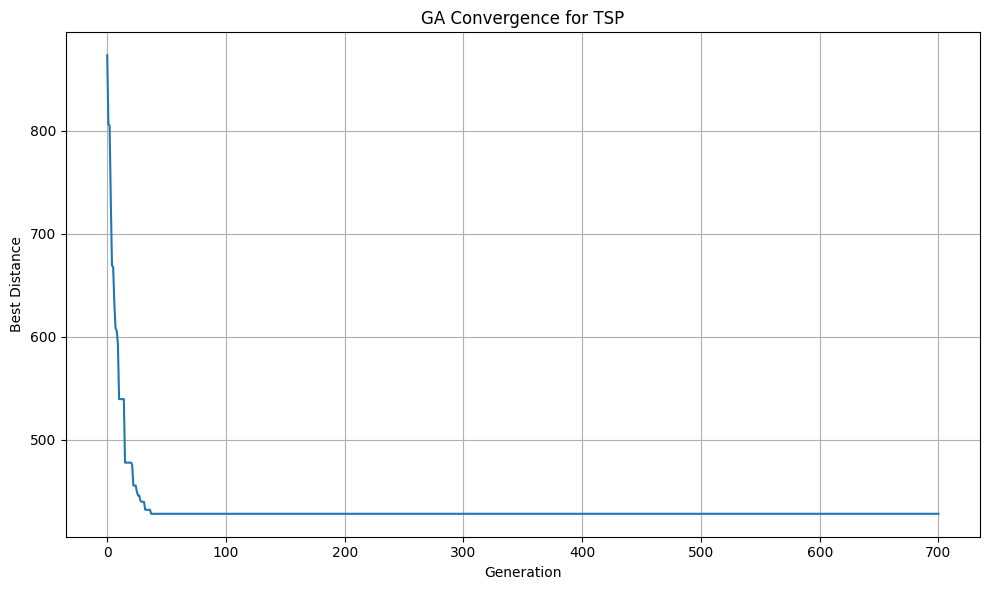

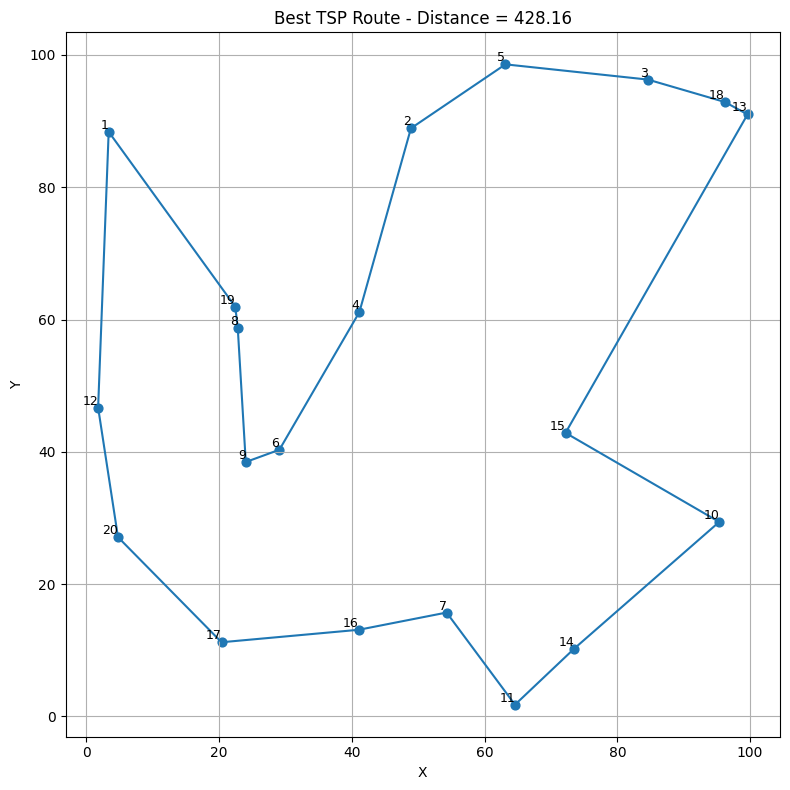

Best distance for 20 cities: 428.1557
Runtime: 6.1704 seconds
Convergence plot saved at: ga_tsp_outputs\convergence_20_cities.png
Best route plot saved at: ga_tsp_outputs\best_route_20_cities.png
Best route GIF saved at: ga_tsp_outputs\best_route_20_cities.gif

Running GA for 50 cities...


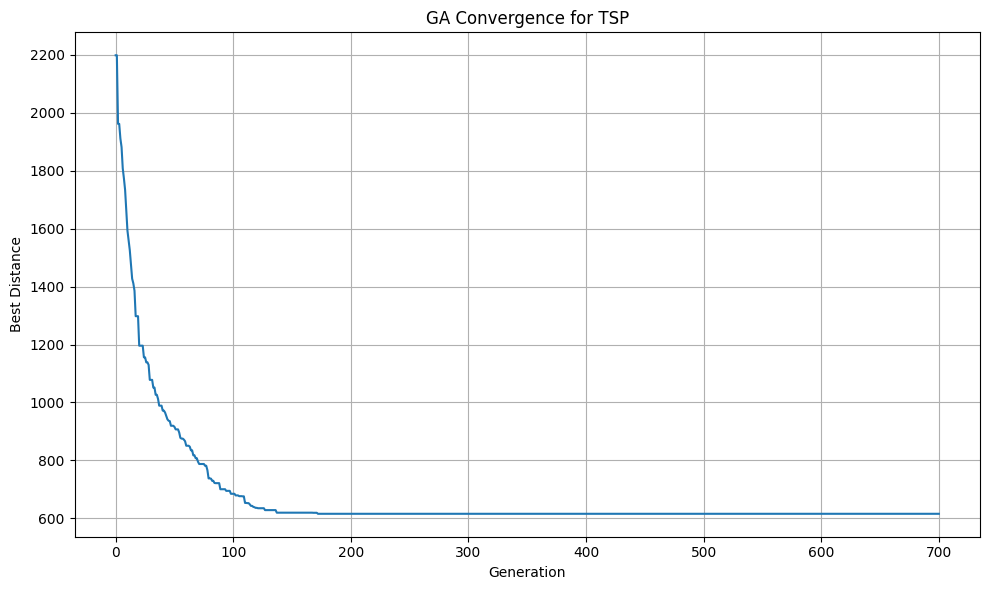

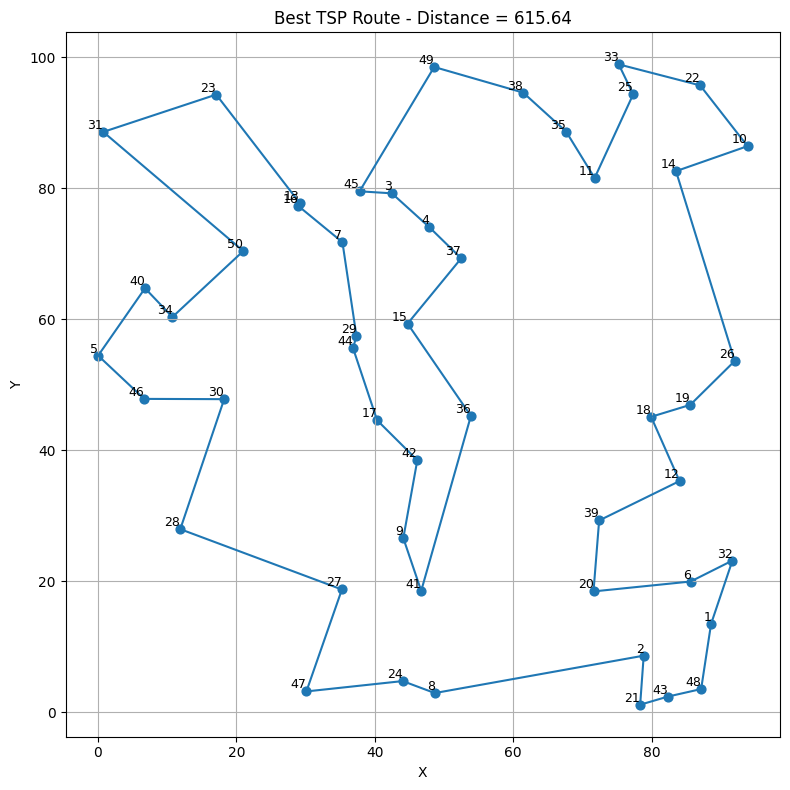

Best distance for 50 cities: 615.6426
Runtime: 17.0817 seconds
Convergence plot saved at: ga_tsp_outputs\convergence_50_cities.png
Best route plot saved at: ga_tsp_outputs\best_route_50_cities.png
Best route GIF saved at: ga_tsp_outputs\best_route_50_cities.gif

Running GA for 100 cities...


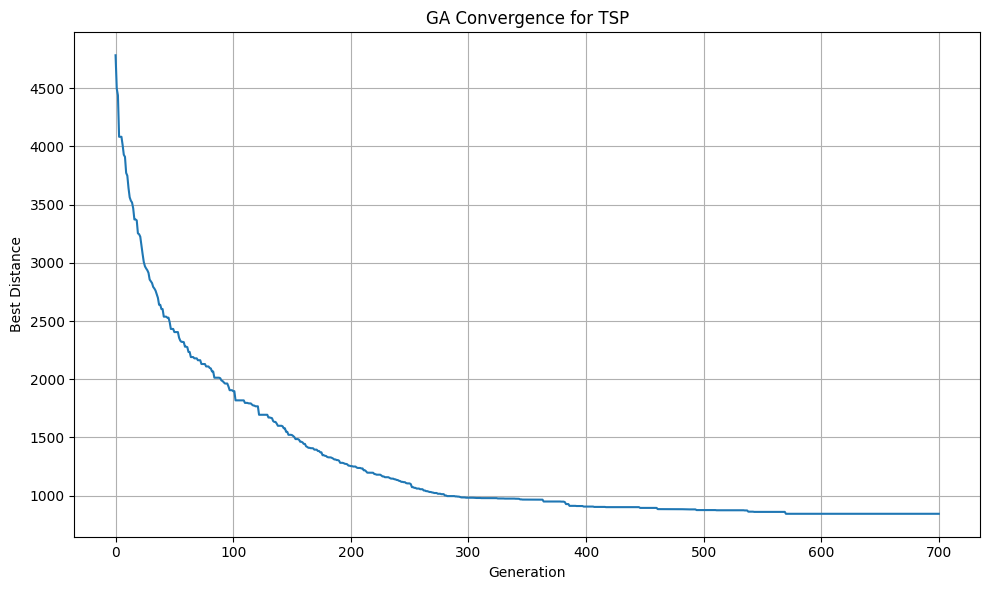

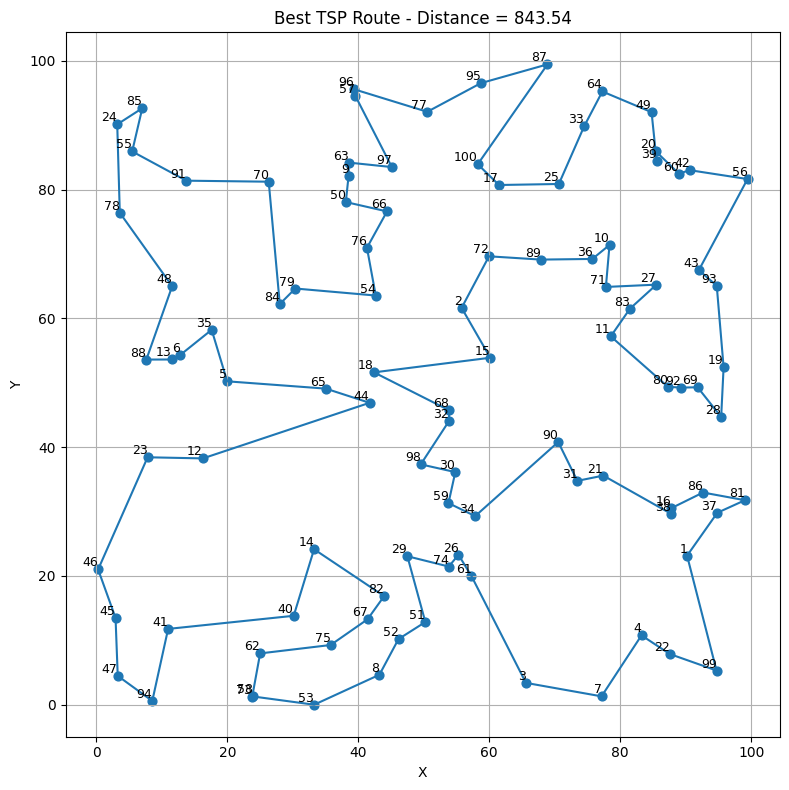

Best distance for 100 cities: 843.5396
Runtime: 44.8216 seconds
Convergence plot saved at: ga_tsp_outputs\convergence_100_cities.png
Best route plot saved at: ga_tsp_outputs\best_route_100_cities.png
Best route GIF saved at: ga_tsp_outputs\best_route_100_cities.gif

Summary of Experiments
------------------------------------------------------------
    Cities |   Best Distance |  Runtime (s)
------------------------------------------------------------
        20 |        428.1557 |       6.1704
        50 |        615.6426 |      17.0817
       100 |        843.5396 |      44.8216
------------------------------------------------------------

Summary CSV saved at: ga_tsp_outputs\summary_results.csv


In [5]:
output_dir = "ga_tsp_outputs"
os.makedirs(output_dir, exist_ok=True)

# این مقادیر را طوری انتخاب کردم که هم جواب قابل قبول بدهد و هم زمان اجرا خیلی زیاد نشود.
config = GAConfig(
    population_size=250,
    generations=700,
    crossover_rate=0.9,
    mutation_rate=0.25,
    tournament_size=5,
    elitism_count=2,
    mutation_type="inversion",
    seed=42
)

test_city_sizes = [20, 50, 100]
results = []

for num_cities in test_city_sizes:
    print()
    print(f"Running GA for {num_cities} cities...")

    result = run_single_experiment(
        num_cities=num_cities,
        output_dir=output_dir,
        config=config
    )

    results.append(result)

    print(f"Best distance for {num_cities} cities: {result['best_distance']:.4f}")
    print(f"Runtime: {result['runtime_seconds']:.4f} seconds")
    print(f"Convergence plot saved at: {result['convergence_plot']}")
    print(f"Best route plot saved at: {result['route_plot']}")
    print(f"Best route GIF saved at: {result['route_gif']}")

summary_path = os.path.join(output_dir, "summary_results.csv")
save_summary(results, summary_path)

print_summary(results)
print()
print(f"Summary CSV saved at: {summary_path}")
